## Mahdi's Things

In [63]:
%pip install SimpleITK 'itkwidgets>=1.0a49' imjoy-elfinder -q

In [2]:
from google.colab import drive  # Imports the drive module from google.colab library.
#
drive.mount('/content/drive')  # Mounts the Google Drive to the specified mount point '/content/drive'.
nifti_dir = r"/content/drive/MyDrive/VUB/Hospital Project/HGUCEGXI.nii"


Mounted at /content/drive


## Hossein's Things

In [3]:
# nifti_dir = r'Dataset\NIFTIs\HGUCEGXI.nii'

## Common Things

In [4]:
from scipy.ndimage import label
import SimpleITK as sitk
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import frangi
from scipy.ndimage import grey_dilation, grey_erosion
from scipy.ndimage import gaussian_filter, grey_opening

sitk_image = sitk.ReadImage(nifti_dir)

In [5]:
def get_region_grown(sitk_image, seed, r, dilation_steps=0):
    # Calculate the average intensity value around the seed point
    seed_value = np.mean([
        sitk.GetArrayFromImage(sitk_image)[seed[0] + i[0], seed[1] + i[1], seed[2] + i[2]]
        for i in [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]
    ])

    # Perform region growing from the seed point with the calculated intensity range
    seg_con = sitk.ConnectedThreshold(sitk_image, seedList=[seed], lower=seed_value - r, upper=seed_value + r)
    temp = sitk.GetArrayFromImage(seg_con)

    # Optionally apply dilation to the grown region
    if dilation_steps != 0:
        temp = cv2.dilate(
            temp.astype(np.uint8),
            np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]).astype(np.uint8),
            iterations=dilation_steps)

    # Return the final grown region
    return temp


def fill_small_holes(mask, max_size):
    # Find connected components in the inverted mask
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(1 - mask.astype(np.uint8))

    # Iterate through each component, filling it if its area is smaller than max_size
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] < max_size:
            mask[labels == i] = 1

    # Return the mask with small holes filled
    return mask


def segment_fat(sitk_image, seed, a_b_range=[-165, -65]):
    # The first region growing for segmenting the fat and surrounding areas
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    temp = sitk.GetArrayFromImage(sitk_image)

    # The second region growing for segmenting the fat and the organs using thresholding
    fat_and_organs = (temp > a_b_range[0]) & (temp < a_b_range[1])

    # Fill small holes in the segmented fat and organs
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs]
    fat_and_organs = np.array(fat_and_organs)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(1, 2, 0)]
    fat_and_organs = np.array(fat_and_organs).transpose(2, 0, 1)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(2, 0, 1)]
    fat_and_organs = np.array(fat_and_organs).transpose(1, 2, 0)

    # Combine the two masks to get the final fat segmentation
    fat = fat_and_organs * fat_and_around

    # Refine the segmentation using connected thresholding
    fat = sitk.ConnectedThreshold(sitk.GetImageFromArray(fat * 100), seedList=[seed], lower=90, upper=110)
    fat = sitk.GetArrayFromImage(fat)

    # Fill any remaining small holes in the final segmentation
    fat = [fill_small_holes(s, 40) for s in fat]
    fat = np.array(fat)

    # Return the final segmented fat region
    return fat

In [6]:
# Hyper parameters
HP = {
    "slice_range": [199, 230],  ## Range of slices for the umbilical region
    "vertical_slice_range": [100, 200],  ## Vertical slice range for the umbilical region

    "slice_no": np.array([10, 11, 12, 13, 18, 19, 20, 21]) + 1,  ## Slices to visualize (1-based index)

    "frangi_scale_range": (1, 2),  ## Scale range for the Frangi vesselness filter
    "frangi_scale_step": 0.2,  ## Step size for the Frangi scale
    "frangi_beta": 1,  ## Beta parameter for the Frangi vesselness filter
    "frangi_gamma": 4,  ## Gamma parameter for the Frangi vesselness filter

    "vessel_size_threshold": 10000,  # Minimum number of pixels for a region to be kept (vessel size threshold)
    "vertical_vessel_size_threshold": 50  ## Threshold for the size of vertical vessels
}

In [7]:
# Convert the SimpleITK image to a numpy array
img = sitk.GetArrayFromImage(sitk_image)

# Define the seed point for segmentation
seed = (215, 120, 300)

# Perform fat segmentation using the provided seed point and attenuation range
fat_seg2 = segment_fat(sitk_image, seed, a_b_range=[-165, -65])

# Modify the image by masking it with the segmented fat region
# First, add 10000 to the image, multiply by the fat segmentation mask, then subtract 10000
img = (img + 10000) * fat_seg2 - 10000

In [59]:
# Define initial percentile values for intensity adjustment
max_value, min_value, upper_gap_value, lower_gap_value = 97, 60, 2, 15

# Create a list of slice objects for the specified ranges in HP
temp = [slice(*HP["slice_range"]), slice(*HP["vertical_slice_range"])]

# Calculate the final gap values for intensity adjustment
upper_gap_value, lower_gap_value = max_value + upper_gap_value, min_value - lower_gap_value

# Compute the percentiles for the specified ranges and fat segmentation mask
max_value, min_value, upper_gap_value, lower_gap_value = np.percentile(
    img[temp[0], temp[1]][fat_seg2[temp[0], temp[1]].astype(bool)],
    [max_value, min_value, upper_gap_value, lower_gap_value]
)

# Adjust the image intensities: clamp values below min_value to lower_gap_value
img[img < min_value] = lower_gap_value

# Adjust the image intensities: clamp values above max_value to upper_gap_value
img[img > max_value] = upper_gap_value

In [123]:
# The credit goes to this repo: "https://github.com/mohakpatel/ImageSliceViewer3D" The code has been changed a bit

import numpy as np
import ipywidgets as ipyw
import matplotlib.pyplot as plt

class ImageSliceViewer3D:

    def __init__(self, volume, filter=None, figsize=(15,10), cmap='gray'):
        self.volume = volume
        self.filter = filter
        self.figsize = figsize
        self.cmap = cmap
        self.v = [np.min(volume), np.max(volume)]

        # Call to select slice plane
        ipyw.interact(self.view_selection, view=ipyw.RadioButtons(
            options=['x-y','y-z', 'z-x'], value='y-z',
            description='Slice plane selection:', disabled=False,
            style={'description_width': 'initial'}))

    def view_selection(self, view):
        # Transpose the volume to orient according to the slice plane selection
        orient = {"y-z":[1,2,0], "z-x":[2,0,1], "x-y": [0,1,2]}
        self.vol = np.transpose(self.volume, orient[view])
        self.filt = np.transpose(self.filter, orient[view])
        maxZ = self.vol.shape[2] - 1

        # Call to view a slice within the selected slice plane
        ipyw.interact(self.plot_slice,
            z=ipyw.IntSlider(min=0, max=maxZ, step=1, continuous_update=False,
            description='Image Slice:'))

    def plot_slice(self, z):
        # Plot slice for the given plane and slice
        self.fig = plt.figure(figsize=self.figsize, dpi=100)
        plt.imshow(self.vol[:,:,z], cmap=plt.get_cmap(self.cmap),
            vmin=self.v[0], vmax=self.v[1])
        if self.filter is not None:
            plt.imshow(self.filt[:,:,z], cmap='hot', alpha=0.5)
        plt.show()

In [61]:
# Crop the image using the specified slice ranges and make a copy
cropped_image = img[temp[0], temp[1]].copy()

# Apply Gaussian filtering to the cropped image
cropped_image = gaussian_filter(cropped_image, sigma=0.4)

# Adjust the intensities in the cropped image: clamp values below min_value to lower_gap_value
cropped_image[cropped_image < min_value] = lower_gap_value

# Adjust the intensities in the cropped image: clamp values above max_value to upper_gap_value
cropped_image[cropped_image > max_value] = upper_gap_value

# Normalize the cropped image to the range [0, 1]
cropped_image = (cropped_image - lower_gap_value) / (upper_gap_value - lower_gap_value)

# Visualize the result
ImageSliceViewer3D(cropped_image)

interactive(children=(RadioButtons(description='Slice plane selection:', index=1, options=('x-y', 'y-z', 'z-x'…

In [11]:
# Apply the Frangi filter to the cropped image
# This enhances vessel-like structures in the image
frangi_slice = frangi(
    cropped_image,
    scale_range=[HP["frangi_scale_range"][0], HP["frangi_scale_range"][1]],  # Range of scales to use in the Frangi filter
    scale_step=HP["frangi_scale_step"],  # Step size for the scales
    beta=HP["frangi_beta"],  # Beta parameter for the Frangi vesselness filter
    gamma=HP["frangi_gamma"],  # Gamma parameter for the Frangi vesselness filter
    black_ridges=False  # Set to False to detect bright ridges (vessels) on a dark background
)

<ipython-input-11-c52c478dc0da>:3: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  frangi_slice = frangi(


In [12]:
# Copy the Frangi filtered image
filtered_frangi = frangi_slice.copy()

# Clip the intensity values to the range between the 1st and 99th percentiles of the non-zero values
filtered_frangi = np.clip(
    filtered_frangi,
    *np.percentile(filtered_frangi[filtered_frangi > 0], [1, 99])
)

# Normalize the filtered image by dividing by the maximum value
filtered_frangi /= np.max(filtered_frangi)

# Set values below the 98th percentile of the non-zero values to zero
filtered_frangi[filtered_frangi < np.percentile(filtered_frangi[filtered_frangi > 0], 98)] = 0

# Zero out a central slice region to remove unwanted structures (artifact removal)
temp = len(cropped_image[0, 0]) // 2
filtered_frangi[:, :, temp-8:temp+8] = 0

# Label connected components in the 3D filtered image
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))

# Remove small connected components (less than 200 pixels)
for i in range(1, np.max(labeled_array) + 1):
    labeled_pixels = labeled_array == i
    if np.sum(labeled_pixels) < 200:
        filtered_frangi[labeled_pixels] = 0

# Apply Gaussian filtering to smooth the image
filtered_frangi = gaussian_filter(filtered_frangi, sigma=0.35)

# Set values below the 70th percentile of the non-zero values to zero
filtered_frangi[filtered_frangi < np.percentile(filtered_frangi[filtered_frangi > 0], 70)] = 0

# Iterate through each slice of the filtered image
for i in range(len(filtered_frangi)):
    # Label connected components in the 2D slice
    labeled_array, _ = label((filtered_frangi[i] > 0), np.ones((3, 3)))

    # Remove small connected components (less than 70 pixels) in each slice
    for j in range(1, np.max(labeled_array) + 1):
        labeled_pixels = labeled_array == j
        if np.sum(labeled_pixels) < 70:
            filtered_frangi[i, labeled_pixels] = 0

# Make a copy of the final filtered Frangi image
yolo = filtered_frangi.copy()

In [13]:
# Copy the final filtered Frangi image to a new variable
filtered_frangi = yolo.copy()

# Label connected components in the 3D filtered image
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))

# Iterate through each connected component
for i in range(1, np.max(labeled_array) + 1):
    labeled_pixels = labeled_array == i

    # Calculate the area of each z-slice within the labeled component
    z_slide_area = np.array([np.sum(labeled_pixels[i]) for i in range(labeled_pixels.shape[0])])
    vect = np.zeros(len(z_slide_area)).astype(bool)
    jump = 0
    l = 5

    # Process each z-slice area
    for i in range(labeled_pixels.shape[0] - l):
        jump -= 1
        area = np.sum(z_slide_area[i:i + l])
        if area > 80 / 5 * l:
            vect[i] = False
            jump = l // 3
            continue
        if jump > 0:
            continue
        vect[i] = True

    # Remove small regions based on the vector criteria
    for i, temp in enumerate(vect):
        if temp:
            filtered_frangi[i, labeled_pixels[i]] = 0

    # Transpose the filtered image to process x-slices
    filtered_frangi = filtered_frangi.transpose(2, 0, 1)
    x_slide_area = np.array([np.sum(labeled_pixels[:, :, i]) for i in range(labeled_pixels.shape[2])])
    vect = np.zeros(len(x_slide_area)).astype(bool)
    jump = 0
    l = len(x_slide_area) // 20

    # Process each x-slice area
    for i in range(labeled_pixels.shape[2] - l):
        jump -= 1
        area = np.sum(x_slide_area[i:i + l])
        if area > 250 / 50 * l:
            vect[i] = False
            jump = l // 3
            continue
        if jump > 0:
            continue
        vect[i] = True

    # Remove small regions based on the vector criteria
    for i, temp in enumerate(vect):
        if temp:
            filtered_frangi[i, labeled_pixels[:, :, i]] = 0

    # Transpose the filtered image back to original orientation
    filtered_frangi = filtered_frangi.transpose(1, 2, 0)

    # Transpose the filtered image to process y-slices
    filtered_frangi = filtered_frangi.transpose(1, 0, 2)
    y_slide_area = np.array([np.sum(labeled_pixels[:, i]) for i in range(labeled_pixels.shape[1])])
    vect = np.zeros(len(y_slide_area)).astype(bool)
    jump = 0
    l = 3

    # Process each y-slice area
    for i in range(labeled_pixels.shape[1] - l):
        jump -= 1
        area = np.sum(y_slide_area[i:i + l])
        if area < 100:
            jump = 1
            continue
        if jump > 0:
            continue
        vect[i] = True

    # Remove small regions based on the vector criteria
    for i, temp in enumerate(vect):
        if temp:
            filtered_frangi[i, labeled_pixels[:, i]] = 0

    # Transpose the filtered image back to original orientation
    filtered_frangi = filtered_frangi.transpose(1, 0, 2)

# Iterate through each slice of the filtered image
for i in range(len(filtered_frangi)):
    # Label connected components in the 2D slice
    labeled_array, _ = label((filtered_frangi[i] > 0), np.ones((3, 3)))

    # Remove small connected components (less than 30 pixels) in each slice
    for j in range(1, np.max(labeled_array) + 1):
        labeled_pixels = labeled_array == j
        if np.sum(labeled_pixels) < 30:
            filtered_frangi[i, labeled_pixels] = 0

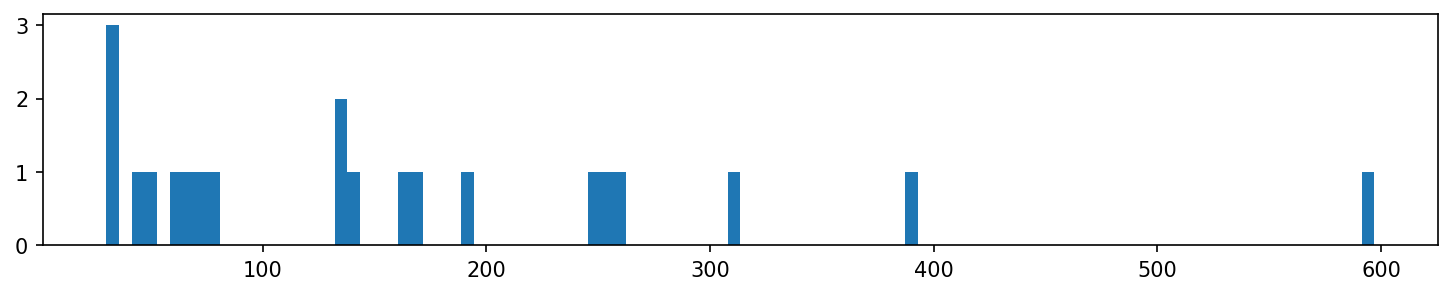

In [14]:
# Label connected components in the 3D filtered image
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))

# Create a histogram of the sizes of the labeled components
plt.figure(figsize=(12, 2), dpi=150)  # Create a new figure with specified size and resolution
plt.hist(
    [np.sum(labeled_array == i) for i in range(1, np.max(labeled_array) + 1)],
    bins=100  # Number of bins in the histogram
)
plt.show()  # Display the histogram

In [64]:
# Optional grey opening (commented out)
# filtered_frangi = grey_opening(filtered_frangi, size=(3, 3, 3))

# Create a temporary mask where filtered_frangi is zero and multiply by yolo
temp = (filtered_frangi == 0) * yolo

# Create subplots with specified figure size and resolution
fig, ax = plt.subplots(len(HP["slice_no"]), 1, figsize=(100, 30), dpi=100)

# Iterate through each specified slice number
for kiri, i in enumerate(HP["slice_no"]):
    # Set the title for the subplot
    ax[kiri].set_title(f"Slice {HP['slice_range'][0] + i}")

    # Display the inverted cropped image in blue colormap
    ax[kiri].imshow(cropped_image[i], cmap="gray")

    # Optionally display vertical dashed lines (commented out)
    # plt.vlines(len(cropped_image[i, 0]) / 2 - 8, 0, 300, color='blue', linestyles='dashed')
    # plt.vlines(len(cropped_image[i, 0]) / 2 + 8, 0, 300, color='blue', linestyles='dashed')

    # Overlay the filtered Frangi mask with transparency
    ax[kiri].imshow(filtered_frangi[i] > 0, alpha=(filtered_frangi[i] > 0).astype(float))

    # Optionally overlay the temporary mask in green (commented out)
    # ax[kiri].imshow(temp[i], cmap='Greens', alpha=(temp[i] > 0).astype(float))

    # Turn off the axis for the subplot
    ax[kiri].axis('off')

# Display the figure
plt.show()


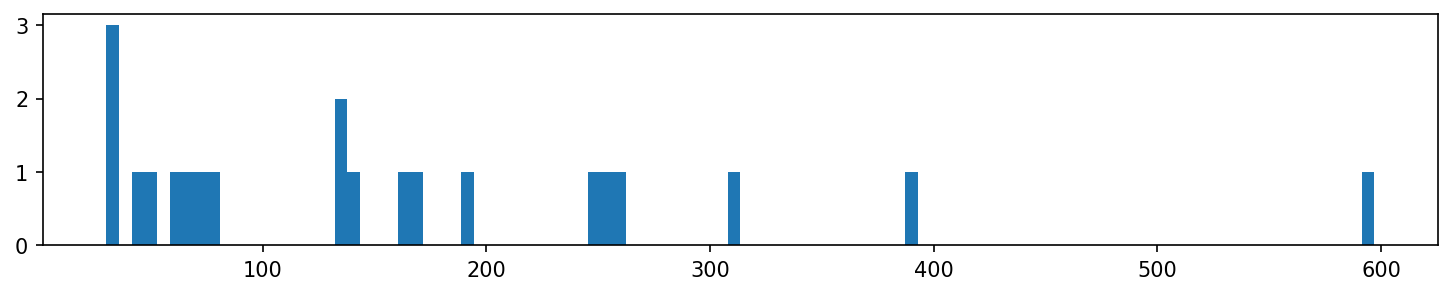

In [16]:
# Label connected components in the 3D filtered image
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))

# Create a new figure for the histogram with specified size and resolution
plt.figure(figsize=(12, 2), dpi=150)

# Create a histogram of the sizes of the labeled components
plt.hist(
    [np.sum(labeled_array == i) for i in range(1, np.max(labeled_array) + 1)],  # Sizes of the labeled components
    bins=100  # Number of bins in the histogram
)

# Display the histogram
plt.show()


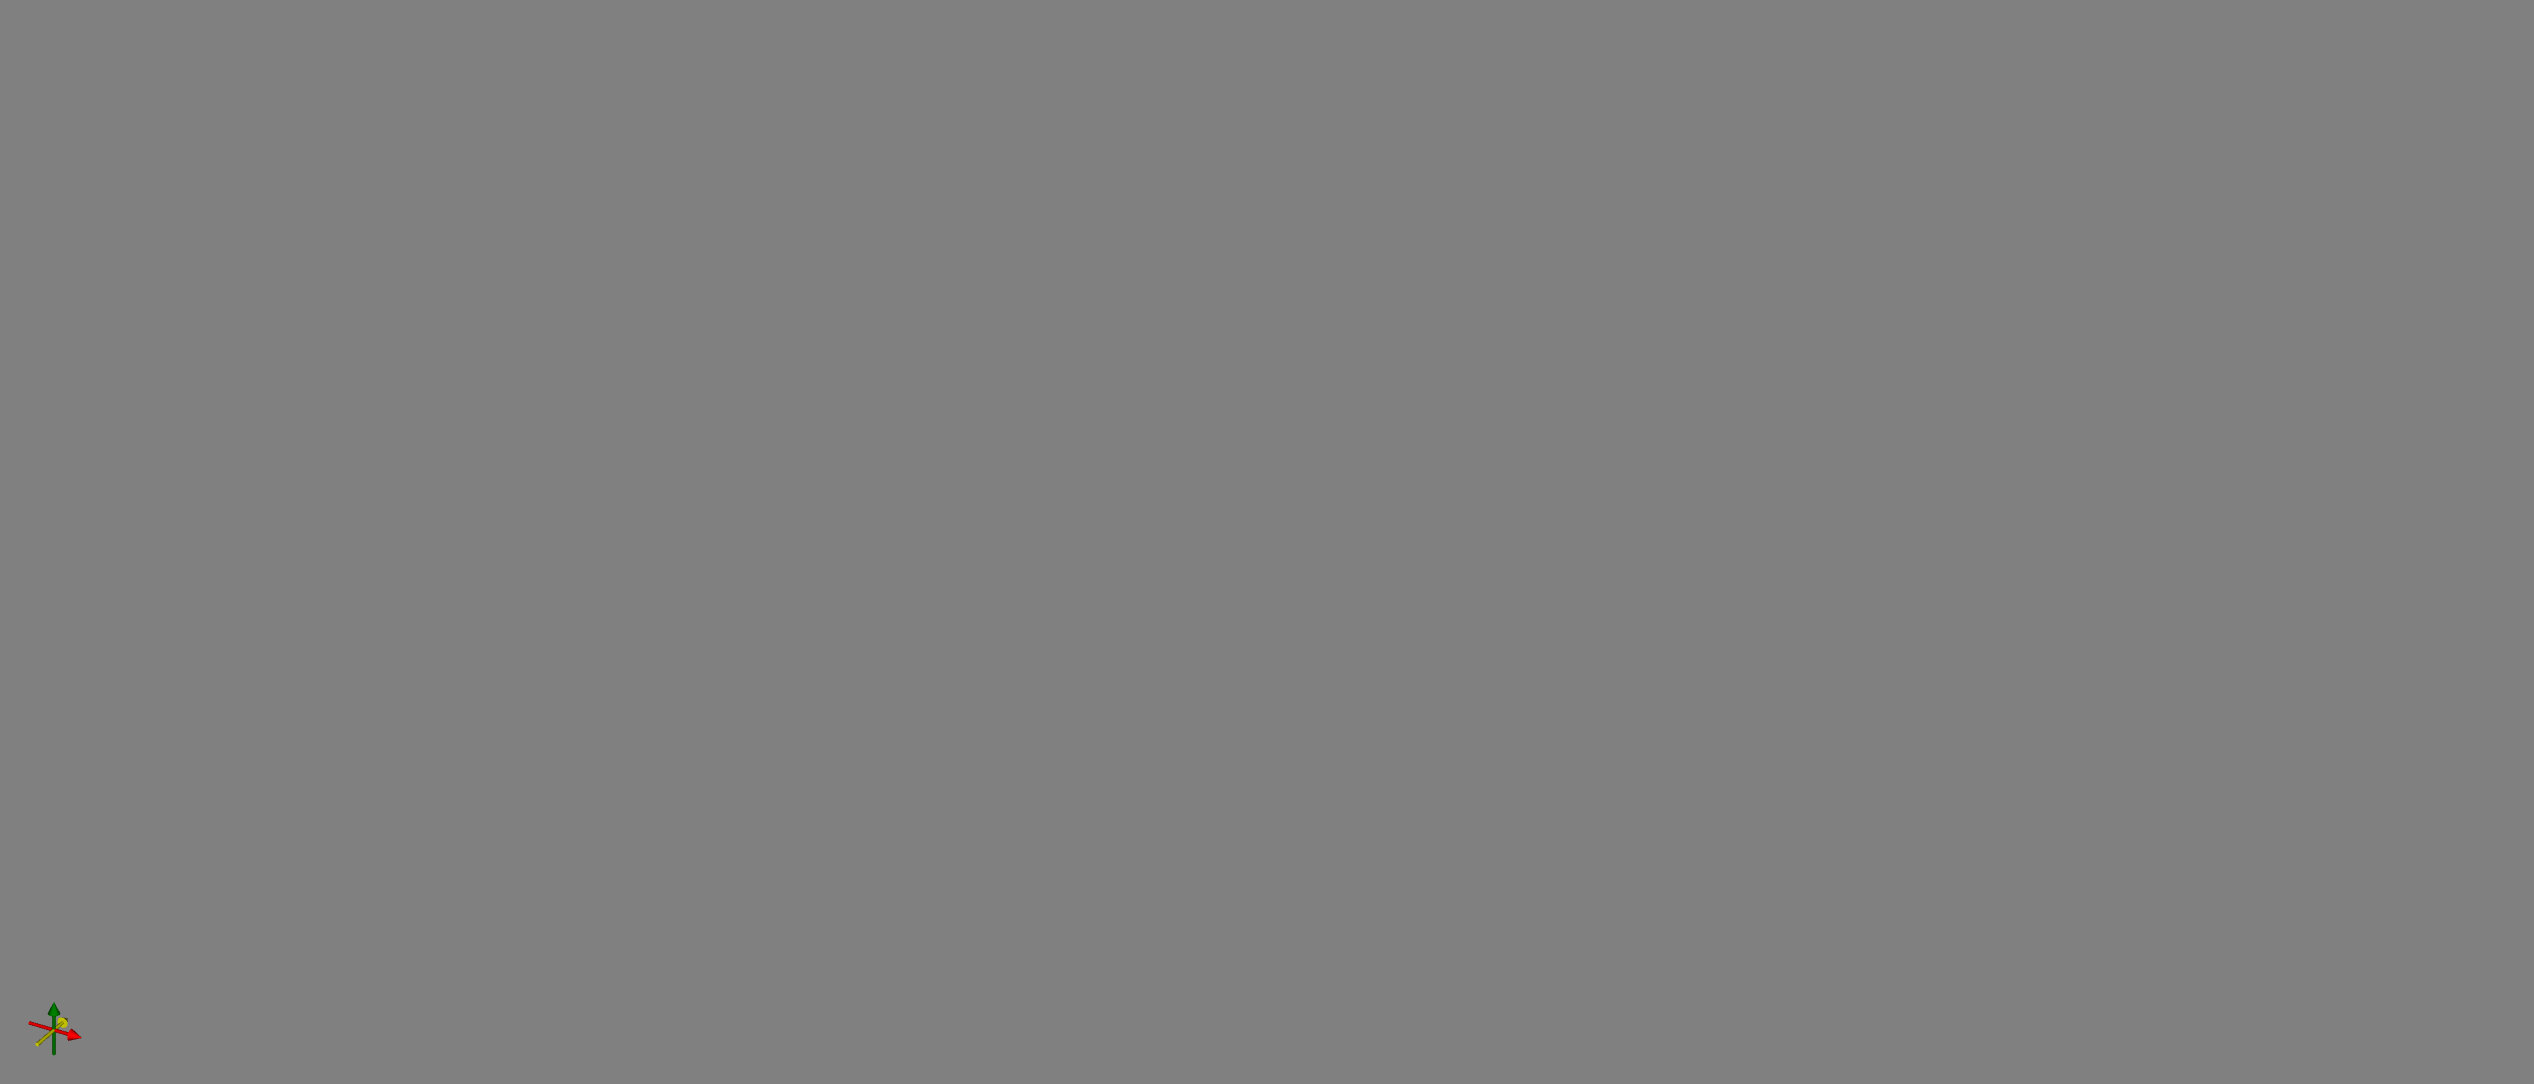
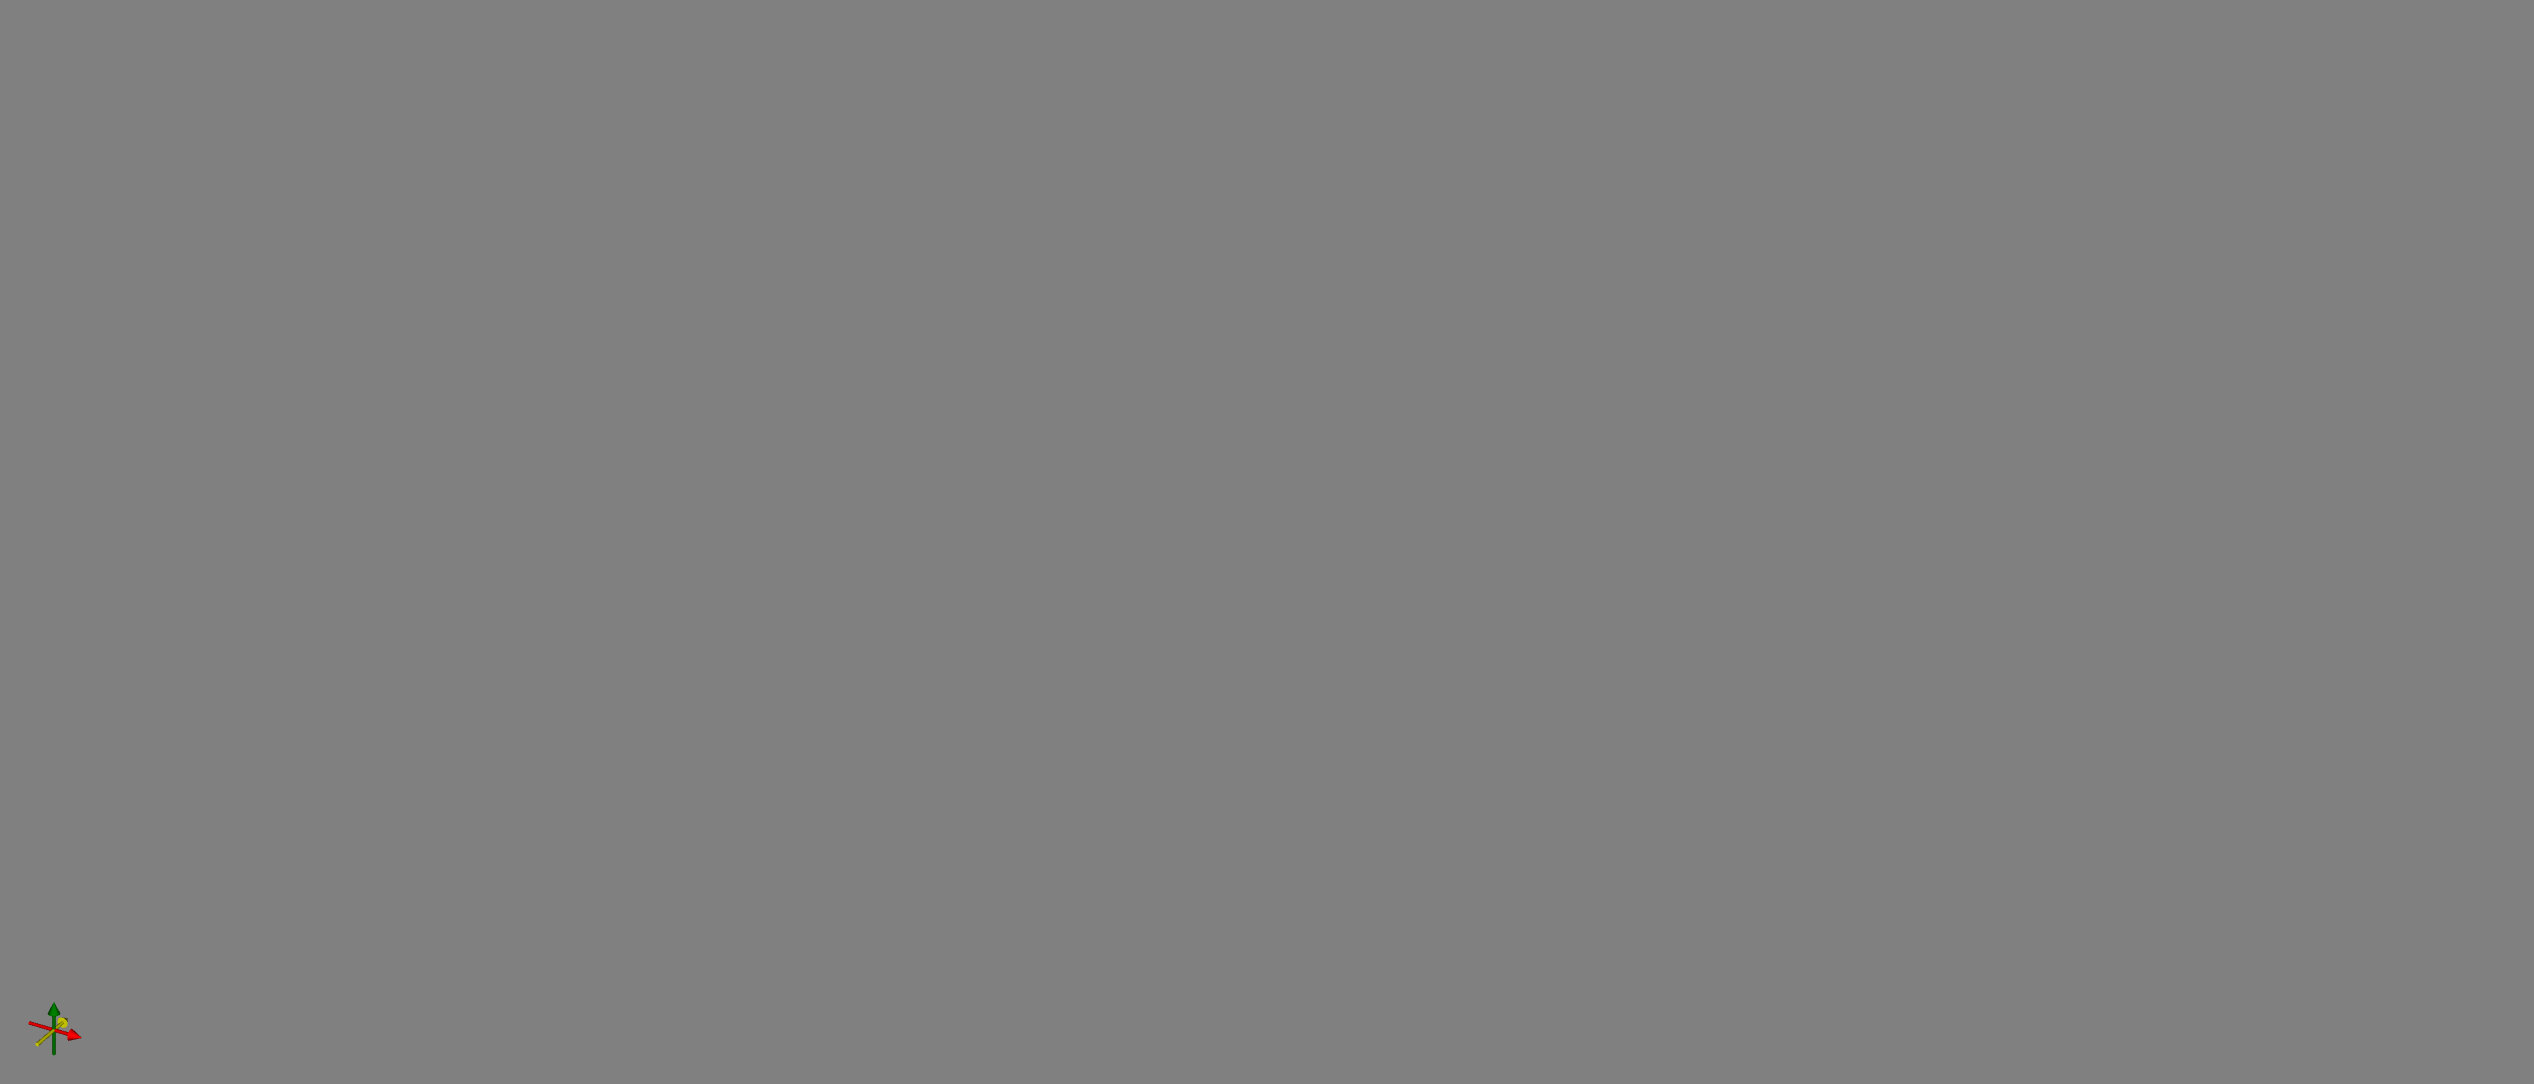

In [204]:
from itkwidgets import view

# # Normalize the cropped image
cropped_image_temp = (cropped_image - np.min(cropped_image)) / (np.max(cropped_image) - np.min(cropped_image))

# # Normalize the filtered image
filtered_frangi_temp = (filtered_frangi - np.min(filtered_frangi)) / (np.max(filtered_frangi) - np.min(filtered_frangi))

# Alpha blending
alpha = 0.5  # Set the alpha value for blending
composite_image = (1 - alpha) * cropped_image_temp + alpha * filtered_frangi_temp

# # Visualize both images together
view(image=composite_image, ui_collapsed=True)

In [125]:
ImageSliceViewer3D(cropped_image_temp, filter=filtered_frangi_temp)

interactive(children=(RadioButtons(description='Slice plane selection:', index=1, options=('x-y', 'y-z', 'z-x'…

In [207]:
from skimage import filters, morphology
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize_3d
from skimage.morphology import binary_closing, binary_opening, ball
from scipy.ndimage import binary_dilation

# If the image is not binary, binarize it using Otsu's thresholding
threshold = filters.threshold_otsu(filtered_frangi_temp)
threshold = 0
binary_vessel_image = filtered_frangi_temp > threshold

# Define a structuring element
selem = ball(0)
# selem = ball(1)

# Perform binary closing to connect nearby components
closed_vessel_image = binary_closing(binary_vessel_image, selem)

# Perform binary opening to remove small noise
cleaned_vessel_image = binary_opening(closed_vessel_image, selem)


# Skeletonize the 3D binary vessel image
skeleton_3d = skeletonize_3d(cleaned_vessel_image)

# Dilate the skeleton slightly to connect nearby components
dilated_skeleton = binary_dilation(skeleton_3d, structure=ball(1))

# Label the dilated skeleton
labeled_skeleton_3d = label(dilated_skeleton)

# Relabel the original skeleton to match the dilated version
skeleton_labels = np.zeros_like(skeleton_3d, dtype=int)
for region in regionprops(labeled_skeleton_3d):
    coords = region.coords
    for coord in coords:
        if skeleton_3d[tuple(coord)]:
            skeleton_labels[tuple(coord)] = region.label

# Measure properties of the skeleton
properties = regionprops(skeleton_labels)
print(f"Number of detected vessels: {len(properties)}")
print("-----------------------")

# Print properties for each labeled region (vessel segment)
for prop in properties:
    print(f"Label: {prop.label}, Area: {prop.area}, Bounding box: {prop.bbox}")
    print("-----------------------")

ImageSliceViewer3D(cropped_image_temp, skeleton_labels)

Number of detected vessels: 19
-----------------------
Label: 1, Area: 9, Bounding box: (0, 35, 288, 2, 44, 294)
-----------------------
Label: 2, Area: 24, Bounding box: (1, 74, 395, 3, 92, 416)
-----------------------
Label: 3, Area: 43, Bounding box: (5, 24, 279, 8, 51, 300)
-----------------------
Label: 4, Area: 52, Bounding box: (6, 23, 324, 10, 59, 353)
-----------------------
Label: 5, Area: 25, Bounding box: (8, 25, 228, 10, 48, 237)
-----------------------
Label: 6, Area: 11, Bounding box: (11, 88, 105, 13, 98, 112)
-----------------------
Label: 7, Area: 18, Bounding box: (12, 27, 188, 15, 35, 198)
-----------------------
Label: 8, Area: 21, Bounding box: (12, 38, 178, 15, 46, 194)
-----------------------
Label: 9, Area: 8, Bounding box: (13, 49, 311, 14, 50, 319)
-----------------------
Label: 10, Area: 12, Bounding box: (13, 50, 194, 14, 53, 206)
-----------------------
Label: 11, Area: 14, Bounding box: (13, 64, 371, 14, 67, 385)
-----------------------
Label: 12, Area: 4

interactive(children=(RadioButtons(description='Slice plane selection:', index=1, options=('x-y', 'y-z', 'z-x'…

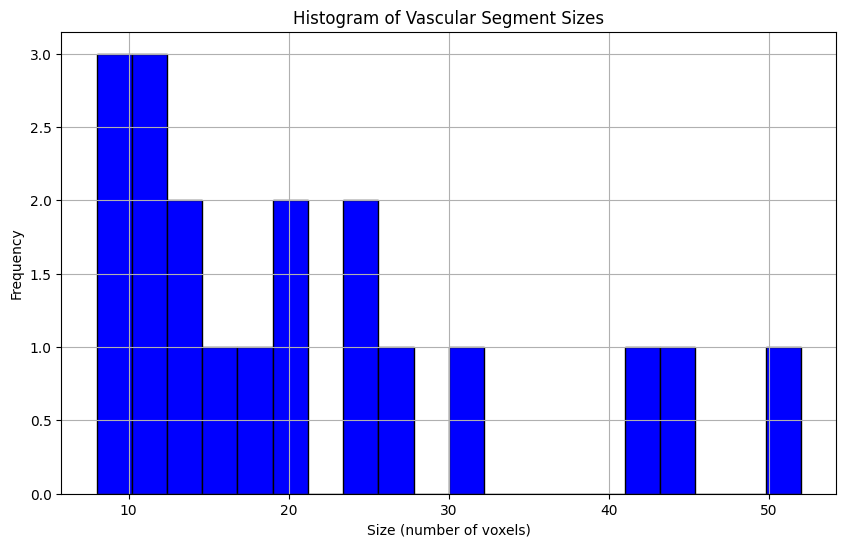

In [208]:
# Extract the sizes of the labeled regions
sizes = [prop.area for prop in properties]

# Plot the histogram of the sizes
plt.figure(figsize=(10, 6))
plt.hist(sizes, bins=20, color='blue', edgecolor='black')
plt.title('Histogram of Vascular Segment Sizes')
plt.xlabel('Size (number of voxels)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [209]:
from scipy.ndimage import distance_transform_edt

# Calculate the distance transform
distance_transform = distance_transform_edt(binary_vessel_image)

RoI = (cropped_image.shape[2] // 4, cropped_image.shape[2] - cropped_image.shape[2] // 4)
# Filter properties based on bounding box
filtered_properties = [prop for prop in properties if prop.bbox[2] > RoI[0] and prop.bbox[5] < RoI[1]]

filtered_labels = np.zeros_like(skeleton_labels, dtype=np.int32)
for prop in filtered_properties:
    filtered_labels[skeleton_labels == prop.label] = prop.label

# Calculate features
features = []

for prop in filtered_properties:
    label_id = prop.label
    coords = prop.coords

    # Diameter: average distance from the centerline
    diameters = [distance_transform[tuple(coord)] * 2 for coord in coords]
    avg_diameter = np.mean(diameters)

    # Length: number of voxels in the skeleton
    length = len(coords)

    # Curvature: simple measure based on the changes in direction
    curvature = 0
    for i in range(1, len(coords) - 1):
        curvature += np.linalg.norm(coords[i-1] - 2 * coords[i] + coords[i+1])
    avg_curvature = curvature / length

    # Branching Points: count neighbors in the skeleton correctly
    branch_points = 0
    for coord in coords:
        z, y, x = coord
        # Extract a 3x3x3 neighborhood around the current voxel
        neighborhood = skeleton_3d[max(z - 1, 0):z + 2, max(y - 1, 0):y + 2, max(x - 1, 0):x + 2]

        # Count the number of neighbors (including the center voxel itself)
        neighbors = np.sum(neighborhood)

        # Subtract 1 to exclude the center voxel itself
        if neighbors > 3*255:
            branch_points += 1

    # Proximity to target area: distance from the center of the ROI
    center_of_roi = np.array([cropped_image.shape[0]//2, cropped_image.shape[1]//2, (RoI[0] + RoI[1])//2])
    distances_to_center = [np.linalg.norm(coord - center_of_roi) for coord in coords]
    avg_distance_to_center = np.mean(distances_to_center)

    # Append features for this vessel
    features.append({
        'label': label_id,
        'avg_diameter': avg_diameter,
        'length': length,
        'avg_curvature': avg_curvature,
        'branch_points': branch_points,
        'avg_distance_to_center': avg_distance_to_center
    })

# Convert features to a structured format for further analysis
import pandas as pd

features_df = pd.DataFrame(features)
features_df

,label,avg_diameter,length,avg_curvature,branch_points,avg_distance_to_center
0,1,3.333333,9,2.731024,0,38.793967
1,3,2.189510,43,2.584867,3,38.999793
2,4,3.060964,52,4.848036,6,83.989351
3,5,2.000000,25,3.712288,0,28.569338
4,7,2.000000,18,1.388559,0,66.671548
5,8,2.703705,21,4.220144,3,69.849874
6,9,2.000000,8,0.000000,0,58.542785
7,10,2.000000,12,1.843710,0,56.547386
8,12,2.570120,45,8.185123,7,48.028062
9,14,2.000000,21,5.258189,1,114.775688


In [202]:
labels = [12, 4]
temp = [prop for prop in filtered_properties if prop.label in labels]

for prop in temp:
    print(f"Label: {prop.label}, Area: {prop.area}, Bounding box: {prop.bbox}")
    print("-----------------------")

# Create a new label array with only the filtered labels
filtered_labels = np.zeros_like(skeleton_labels, dtype=np.int32)
for prop in temp:
    filtered_labels[skeleton_labels == prop.label] = prop.label

# Visualize the original image with the filtered labels
ImageSliceViewer3D(cropped_image, filter=filtered_labels)

Label: 4, Area: 52, Bounding box: (6, 23, 324, 10, 59, 353)
-----------------------
Label: 12, Area: 45, Bounding box: (20, 19, 290, 23, 35, 308)
-----------------------


interactive(children=(RadioButtons(description='Slice plane selection:', index=1, options=('x-y', 'y-z', 'z-x'…

In [203]:
# 0: not a vessel, 1: a good recognized vessel, 2: part of a vessel (only captured part of the vessel. The filtering is bad)
manual_annotation = [2, 1, 1, 1, 2, 2, 1, 2, 1, 0, 1, 2, 1, 1, 0]

features_df["is_vessel"] = manual_annotation
features_df

,label,avg_diameter,length,avg_curvature,branch_points,avg_distance_to_center,is_vessel
0,1,3.333333,9,2.731024,0,38.793967,2
1,3,2.189510,43,2.584867,3,38.999793,1
2,4,3.060964,52,4.848036,6,83.989351,1
3,5,2.000000,25,3.712288,0,28.569338,1
4,7,2.000000,18,1.388559,0,66.671548,2
5,8,2.703705,21,4.220144,3,69.849874,2
6,9,2.000000,8,0.000000,0,58.542785,1
7,10,2.000000,12,1.843710,0,56.547386,2
8,12,2.570120,45,8.185123,7,48.028062,1
9,14,2.000000,21,5.258189,1,114.775688,0
